## Notebook 01: EDA

**Competition:** [Human or AI? — Cornell Tech CS5785](https://www.kaggle.com/competitions/cornell-tech-cs-5785-combined-2026-ai-vs-human-text)
**Metric:** AUROC based on prediction P(AI-Generated)

## Setup
Create a directory "data" and you can drop the competition data there to get started

In [1]:
import re
import subprocess
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline, make_union
from sklearn.preprocessing import Normalizer

COMPETITION = "cornell-tech-cs-5785-combined-2026-ai-vs-human-text"
DATA_DIR = Path("../data")
SEED = 77

HUMAN_COLOR, AI_COLOR = "#4C72B0", "#DD8452"
SPLIT_COLORS = {"train": "#4C72B0", "unlabeled": "#55A868", "test": "#C44E52"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

In [2]:
if not (DATA_DIR / "train.csv").exists():
    DATA_DIR.mkdir(exist_ok=True)
    subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", str(DATA_DIR)], check=True)
    with zipfile.ZipFile(DATA_DIR / f"{COMPETITION}.zip") as z:
        z.extractall(DATA_DIR)

train = pd.read_csv(DATA_DIR / "train.csv")
unlabeled = pd.read_csv(DATA_DIR / "unlabeled.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
starter = pd.read_csv(DATA_DIR / "train_starter_2000.csv")

splits = {"train": train, "unlabeled": unlabeled, "test": test}

## 1. Datasets

We have 10,000 training, 3,000 unlabeled, and 3,000 test entries

In [3]:
pd.DataFrame({
    name: {
        "rows": len(df),
        "null texts": df["text"].isna().sum(),
        "id min": df["id"].min(),
        "id max": df["id"].max(),
    }
    for name, df in splits.items()
}).T

,rows,null texts,id min,id max
train,10000,0,1,10000
unlabeled,3000,0,10001,13000
test,3000,0,13001,16000


In [4]:
print("Train label counts:", train["label"].value_counts().sort_index().to_dict(), "(0 = human, 1 = AI)")

starter_merged = starter.merge(train, on="id", suffixes=("_starter", "_train"))
print("Starter rows found in train:", len(starter_merged), "/", len(starter))
print("Starter text and label identical to train:",
      (starter_merged["text_starter"] == starter_merged["text_train"]).all()
      and (starter_merged["label_starter"] == starter_merged["label_train"]).all())

Train label counts: {0: 5000, 1: 5000} (0 = human, 1 = AI)
Starter rows found in train: 2000 / 2000
Starter text and label identical to train: True


In [5]:
def peek(text, n=200):
    return text[:n].replace("\n", " ⏎ ") + " …"

for label, name in [(0, "Human Examples"), (1, "AI Examples")]:
    print(f"{name}")
    for text in train.loc[train["label"] == label, "text"].sample(3, random_state=SEED):
        print("•", peek(text), "\n")

Human Examples
• I had a WZ update a couple days ago, a small one but before I checked the performance, I turned on GPU scheduling just to see if I get better performance. When I finally started the game, it was unpla … 

• Semantic image segmentation is one of fastest growing areas in computer ⏎ vision with a variety of applications. In many areas, such as robotics and ⏎ autonomous vehicles, semantic image segmentation is c … 

• Anyone ever wonder where the gang went to college? We know that Howard went to MIT and Leonard went to Princeton but what about Sheldon and Raj? Sheldon’s brother George did say “all the extra money w … 

AI Examples
• Quentin Tarantino has said he wants to direct a new instalment in the Friday horror franchise, which began with 1984's A Nightmare on Elm Street. ⏎  ⏎ The director told Empire magazine that he had been ap … 

• Linda Andrews (born November 18, 1968) is an American singer, songwriter and actress. She has released five albums and has appeared in 

**TLDR:** data is balanced (5,000 / 5,000), and `train_starter_2000.csv` is just a subset of train

## 2. Check duplicates & leakage

In [6]:
def normalize_text(text):
    return re.sub(r"\s+", " ", text.lower()).strip()

normed = {name: df["text"].map(normalize_text) for name, df in splits.items()}

print("Duplicates in each split:")
for name, texts in normed.items():
    print(f"  {name:<10} {texts.duplicated().sum()}")

print("Overlaps across splits:")
for a, b in [("train", "unlabeled"), ("train", "test"), ("unlabeled", "test")]:
    print(f"  {a} ∩ {b}: {len(set(normed[a]) & set(normed[b]))}")

Duplicates in each split:
  train      0
  unlabeled  0
  test       0
Overlaps across splits:
  train ∩ unlabeled: 0
  train ∩ test: 0
  unlabeled ∩ test: 0


Exact matches might miss a near-copy, so for every unlabeled/test passage we can find its most similar **train** passage by TF-IDF cosine similarity

unlabeled  nearest-train similarity: median=0.23, >0.8: 3
test       nearest-train similarity: median=0.19, >0.8: 1


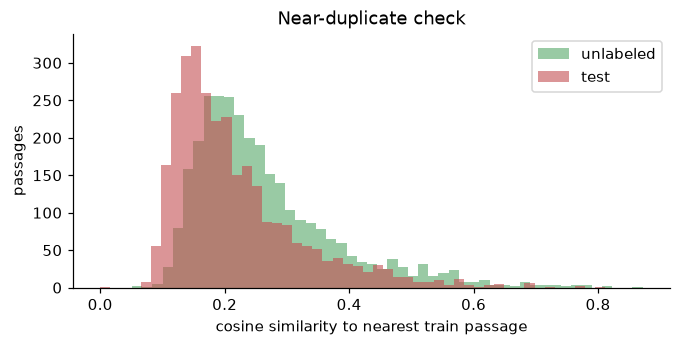

In [7]:
dup_vec = TfidfVectorizer(sublinear_tf=True, min_df=2).fit(pd.concat([df["text"] for df in splits.values()]))
nn = NearestNeighbors(n_neighbors=1, metric="cosine").fit(dup_vec.transform(train["text"]))

fig, ax = plt.subplots(figsize=(7, 3))
for name in ["unlabeled", "test"]:
    dist, _ = nn.kneighbors(dup_vec.transform(splits[name]["text"]))
    sim = 1 - dist.ravel()
    ax.hist(sim, bins=50, alpha=0.6, color=SPLIT_COLORS[name], label=name)
    print(f"{name:<10} nearest-train similarity: median={np.median(sim):.2f}, >0.8: {(sim > 0.8).sum()}")
ax.set(xlabel="cosine similarity to nearest train passage", ylabel="passages", title="Near-duplicate check")
ax.legend();

**Order leak check:** we can guess based on `id` order alone, labelAUROC ≈ 0.5 means no leak

In [8]:
print(f"AUROC of id vs label: {roc_auc_score(train['label'], train['id']):.3f}")
train.groupby(pd.qcut(train["id"], 10, labels=False))["label"].mean().rename("AI share by id decile").to_frame().T

AUROC of id vs label: 0.495


id,0,1,2,3,4,5,6,7,8,9
AI share by id decile,0.504,0.531,0.498,0.502,0.503,0.474,0.493,0.474,0.514,0.507


**TLDR:** no duplicates and no leakage! Test passages are not near-copies of training passages either

## 3. Looking at passage length
LLM output can often be wordy, so checking if length is a giveaway

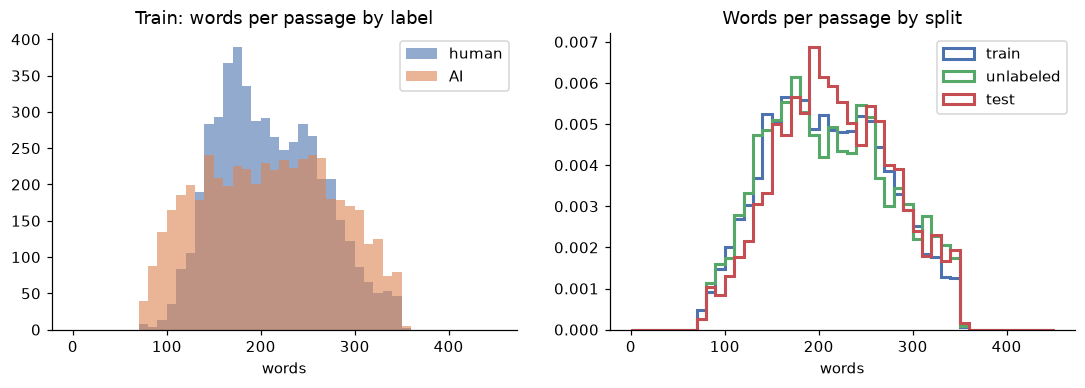

In [9]:
def split_sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s]

def length_features(texts):
    return pd.DataFrame({
        "n_chars": texts.str.len(),
        "n_words": texts.str.split().str.len(),
        "n_sentences": texts.map(lambda t: len(split_sentences(t))),
    })

lengths = {name: length_features(df["text"]) for name, df in splits.items()}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.linspace(0, 450, 46)
for label, name, color in [(0, "human", HUMAN_COLOR), (1, "AI", AI_COLOR)]:
    axes[0].hist(lengths["train"].loc[train["label"] == label, "n_words"], bins=bins, alpha=0.6, color=color, label=name)
axes[0].set(title="Train: words per passage by label", xlabel="words")
axes[0].legend()
for name, feats in lengths.items():
    axes[1].hist(feats["n_words"], bins=bins, density=True, histtype="step", lw=2, color=SPLIT_COLORS[name], label=name)
axes[1].set(title="Words per passage by split", xlabel="words")
axes[1].legend();

In [10]:
summary = pd.concat({
    "human": lengths["train"][train["label"] == 0].median(),
    "AI": lengths["train"][train["label"] == 1].median(),
    **{name: feats.median() for name, feats in lengths.items() if name != "train"},
}, axis=1)
summary["AUROC (train)"] = [roc_auc_score(train["label"], lengths["train"][c]) for c in summary.index]
summary.round(3)

,human,AI,unlabeled,test,AUROC (train)
n_chars,1222.0,1278.0,1260.0,1247.0,0.526
n_words,204.0,209.0,206.5,213.0,0.498
n_sentences,10.0,9.0,10.0,10.0,0.434


**TLDR:** Word count was balanced between human and AI passages, so length on its own doesn't tell us much

## 4. Style features

Checking for basic style features, scoring with AUROC on train. AUROC > 0.5 points means more common among AI, < 0.5 means more common among human

In [11]:
try:
    import os, certifi, nltk
    os.environ.setdefault("SSL_CERT_FILE", certifi.where())
    nltk.download("words", quiet=True)
    from nltk.corpus import words as nltk_words
    ENGLISH_WORDS = {w.lower() for w in nltk_words.words()}
except Exception as err:
    print("nltk words list unavailable, skipping OOV feature:", err)
    ENGLISH_WORDS = None

PUNCTUATION = {
    "comma": r",", "semicolon": r";", "colon": r":", "exclamation": r"!", "question": r"\?",
    "em_dash": r"—", "en_dash": r"–", "hyphen": r"(?<=\w)-(?=\w)", "paren": r"\(",
    "straight_quote": r'"', "curly_quote": r"[“”‘’]", "apostrophe": r"'", "ellipsis": r"\.\.\.|…",
}

def style_features(texts):
    tokens = texts.str.split()
    n_words = tokens.str.len()
    n_chars = texts.str.len()
    lower_words = texts.str.lower().str.findall(r"[a-z]+")
    sent_lens = texts.map(lambda t: [len(s.split()) for s in split_sentences(t)])

    feats = pd.DataFrame({
        "mean_word_length": lower_words.map(lambda ws: np.mean([len(w) for w in ws]) if ws else 0),
        "type_token_ratio": lower_words.map(lambda ws: len(set(ws)) / max(len(ws), 1)),
        "mean_sentence_length": sent_lens.map(np.mean),
        "sentence_length_std": sent_lens.map(np.std),
        "uppercase_ratio": texts.str.count(r"[A-Z]") / n_chars,
        "digit_ratio": texts.str.count(r"\d") / n_chars,
        "non_ascii_ratio": texts.str.count(r"[^\x00-\x7f]") / n_chars,
        "newlines_per_100w": texts.str.count("\n") / n_words * 100,
        "lowercase_i_per_100w": texts.str.count(r"\bi\b") / n_words * 100,
        "double_space_per_100w": texts.str.count(r"  ") / n_words * 100,
    })
    for name, pattern in PUNCTUATION.items():
        feats[f"{name}_per_100w"] = texts.str.count(pattern) / n_words * 100
    if ENGLISH_WORDS:
        feats["oov_rate"] = lower_words.map(lambda ws: np.mean([w not in ENGLISH_WORDS for w in ws]) if ws else 0)
    return feats

style = {name: style_features(df["text"]) for name, df in splits.items()}

,AUROC,higher for
exclamation_per_100w,0.601,AI
colon_per_100w,0.600,AI
newlines_per_100w,0.590,AI
mean_word_length,0.589,AI
type_token_ratio,0.574,AI
apostrophe_per_100w,0.561,AI
oov_rate,0.549,AI
mean_sentence_length,0.547,AI
ellipsis_per_100w,0.534,AI
straight_quote_per_100w,0.515,AI


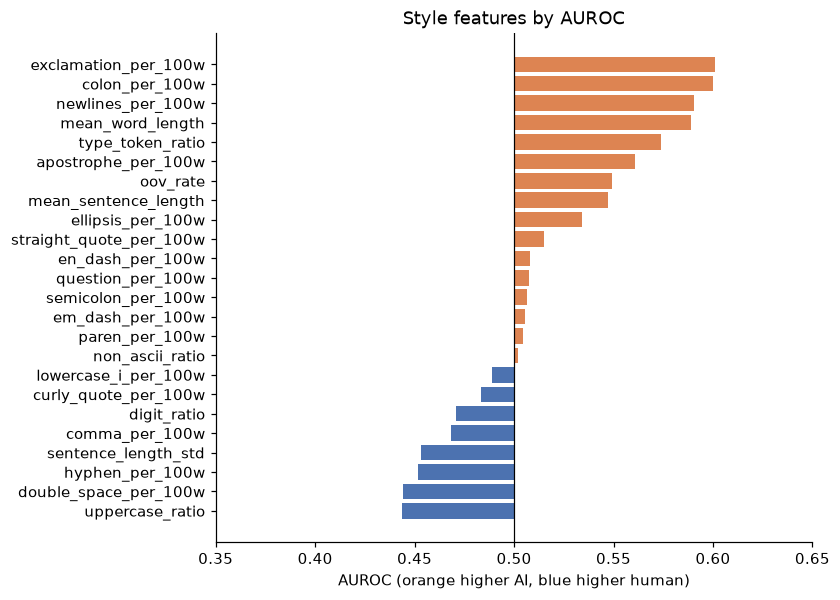

In [12]:
style_auc = pd.DataFrame({
    "AUROC": [roc_auc_score(train["label"], style["train"][c]) for c in style["train"].columns],
}, index=style["train"].columns)
style_auc["higher for"] = np.where(style_auc["AUROC"] > 0.5, "AI", "human")
style_auc = style_auc.sort_values("AUROC", ascending=False)
display(style_auc.head(10).round(3))

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(style_auc.index[::-1], style_auc["AUROC"][::-1] - 0.5, left=0.5,
        color=np.where(style_auc["AUROC"][::-1] > 0.5, AI_COLOR, HUMAN_COLOR))
ax.axvline(0.5, color="black", lw=0.8)
ax.set(xlim=(0.35, 0.65), xlabel="AUROC (orange higher AI, blue higher human)", title="Style features by AUROC");

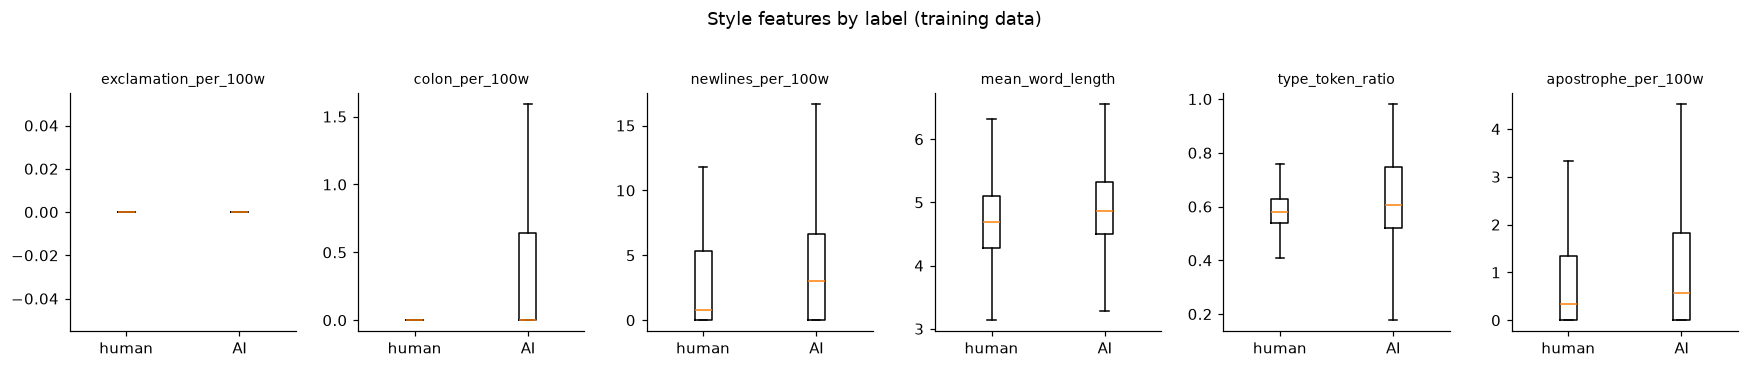

In [13]:
top_style = style_auc.index[:6]
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, col in zip(axes, top_style):
    values = style["train"][col]
    cap = values.quantile(0.99)
    ax.boxplot([values[train["label"] == 0].clip(upper=cap), values[train["label"] == 1].clip(upper=cap)],
               tick_labels=["human", "AI"], showfliers=False)
    ax.set_title(col, fontsize=9)
fig.suptitle("Style features by label (training data)", y=1.03)
fig.tight_layout();

**Checking signals in test + unlabeled:** Comparing the means of the top features across the human and AI rows of train and across the unlabeled and test splits

In [14]:
pd.concat({
    "train human": style["train"][train["label"] == 0][top_style].mean(),
    "train AI": style["train"][train["label"] == 1][top_style].mean(),
    "unlabeled": style["unlabeled"][top_style].mean(),
    "test": style["test"][top_style].mean(),
}, axis=1).round(3)

,train human,train AI,unlabeled,test
exclamation_per_100w,0.039,0.235,0.104,0.175
colon_per_100w,0.166,0.419,0.279,0.226
newlines_per_100w,2.843,5.310,3.871,5.502
mean_word_length,4.713,4.937,4.833,4.649
type_token_ratio,0.583,0.624,0.592,0.584
apostrophe_per_100w,0.924,1.410,1.138,1.248


**TLDR:** each style feature is weak on its own, and test looks AI-like on newlines and human-like on word length. Could be useful as supporting features.

## 5. Vocab

We can use weighted log-odds to find overused words by each AI and humans

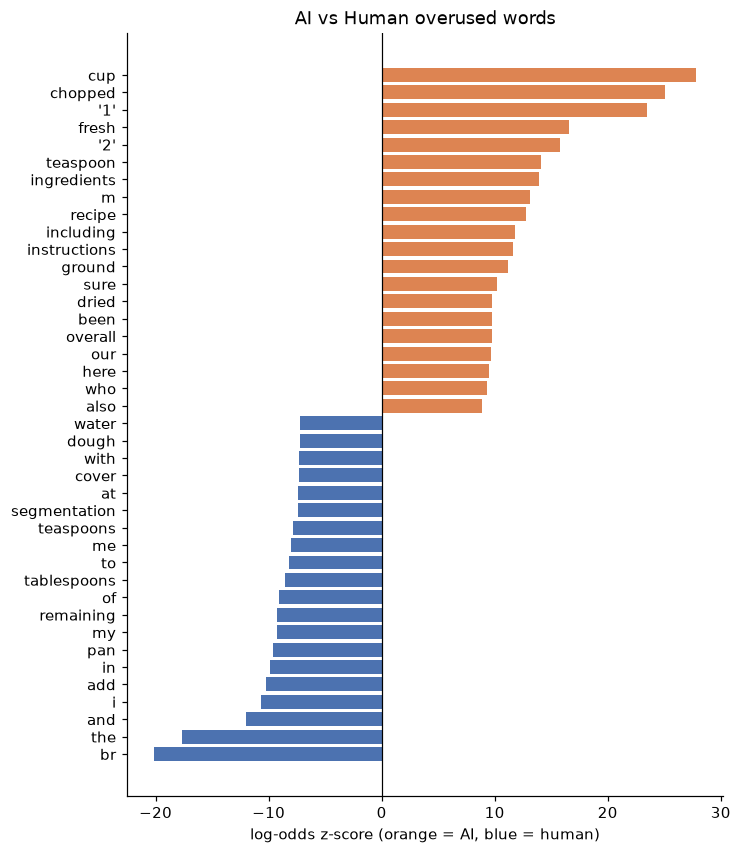

In [15]:
def log_odds_z(texts, labels, **vectorizer_kwargs):
    """z-scored log-odds of each term being used in AI (positive) vs human (negative)"""
    vec = CountVectorizer(**vectorizer_kwargs)
    X = vec.fit_transform(texts)
    ai = np.asarray(X[labels.values == 1].sum(axis=0)).ravel()
    human = np.asarray(X[labels.values == 0].sum(axis=0)).ravel()
    prior = ai + human
    n_ai, n_human, n_prior = ai.sum(), human.sum(), prior.sum()
    delta = (np.log((ai + prior) / (n_ai + n_prior - ai - prior))
             - np.log((human + prior) / (n_human + n_prior - human - prior)))
    z = delta / np.sqrt(1 / (ai + prior) + 1 / (human + prior))
    return pd.Series(z, index=vec.get_feature_names_out()).sort_values()

def plot_log_odds(z, title, n=20):
    top = pd.concat([z.head(n), z.tail(n)])
    fig, ax = plt.subplots(figsize=(7, 9))
    ax.barh([repr(t) if " " in t or not t.isalpha() else t for t in top.index], top.values,
            color=np.where(top.values > 0, AI_COLOR, HUMAN_COLOR))
    ax.axvline(0, color="black", lw=0.8)
    ax.set(xlabel="log-odds z-score (orange = AI, blue = human)", title=title)

word_z = log_odds_z(train["text"], train["label"], lowercase=True, min_df=5, token_pattern=r"(?u)\b\w+\b")
plot_log_odds(word_z, "AI vs Human overused words")

**Trying known LLM vocab"** Checking some words that are reported as overused by chat models, comparing across classes and splits. Part of this is making sure the test split doesn't have a very different generator.

In [16]:
TELLS = ["delve", "moreover", "furthermore", "additionally", "crucial", "tapestry", "vibrant",
         "testament", "landscape", "foster", "pivotal", "intricate", "in conclusion", "overall", "notably"]

def tell_rates(texts):
    lower = texts.str.lower()
    return pd.Series({w: lower.str.contains(rf"\b{w}\b").mean() * 100 for w in TELLS})

pd.DataFrame({
    "train human %": tell_rates(train.loc[train["label"] == 0, "text"]),
    "train AI %": tell_rates(train.loc[train["label"] == 1, "text"]),
    "unlabeled %": tell_rates(unlabeled["text"]),
    "test %": tell_rates(test["text"]),
}).round(1).sort_values("train AI %", ascending=False)

,train human %,train AI %,unlabeled %,test %
overall,2.3,10.9,6.0,2.7
additionally,0.7,2.7,1.7,1.0
furthermore,1.4,2.1,1.4,0.9
crucial,0.9,1.5,1.6,1.1
moreover,1.8,1.1,1.2,0.8
testament,0.2,0.6,0.4,1.1
vibrant,0.0,0.5,0.5,0.7
landscape,0.3,0.5,0.6,1.0
intricate,0.1,0.5,0.2,0.4
in conclusion,0.1,0.5,0.4,0.4


**TLDR:** The biggest tells for AI-generated text was in passages of specific tasks. For example, in training cooking recipes, AI uses `1/2 cup` ingredient lists and markdown bullets (`- `, `*`). Similarly, human text uses IMDB `<br />` tags and first-person `I`/`my` that don't show up as often in AI-generated text. There was some variation across training and test passages, as `overall` shows up in 10.9% of train AI passages but only 2.7% of test passages.

## 6. Distribution shift (adversarial validation)

Since we're seeing variations across the training and test data, we can train a classifier to tell which split in the data a passage came from:
- AUROC near 0.5 means the two splits are indistinguishable.
- AUROC near 1.0 means they're very different, so CV on train will overestimate test performance

In [17]:
def adversarial_validation(a, b, n_terms=12):
    texts = pd.concat([a, b], ignore_index=True)
    y = np.r_[np.zeros(len(a)), np.ones(len(b))]
    vec = TfidfVectorizer(sublinear_tf=True, min_df=3, ngram_range=(1, 2), max_features=50_000)
    X = vec.fit_transform(texts)
    clf = LogisticRegression(C=1.0, max_iter=2000)
    oof = cross_val_predict(clf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
    coefs = pd.Series(clf.fit(X, y).coef_[0], index=vec.get_feature_names_out()).sort_values()
    return roc_auc_score(y, oof), oof[: len(a)], coefs.head(n_terms).index.tolist(), coefs.tail(n_terms)[::-1].index.tolist()

adv_rows, train_test_likeness = [], None
for a, b in [("train", "test"), ("train", "unlabeled"), ("unlabeled", "test")]:
    auc, oof_a, terms_a, terms_b = adversarial_validation(splits[a]["text"], splits[b]["text"])
    adv_rows.append({"pair": f"{a} vs {b}", "AUROC": auc, f"terms -> first split": ", ".join(terms_a), "terms -> second split": ", ".join(terms_b)})
    if (a, b) == ("train", "test"):
        train_test_likeness = oof_a

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(adv_rows).set_index("pair"))

,AUROC,terms -> first split,terms -> second split
pair,,,
train vs test,0.733,"was, film, overall, br, 10, the film, movie, he was, if, have, experience, br br","his, the novel, love, novel, and the, young, the, heart, the book, her, poem, book"
train vs unlabeled,0.590,"put, would be, high, what, label, net, up to, graphs, down, one, cases, section","european, return, sweet, object, bowl combine, research, popular, as the, of the, they are, this, serve"
unlabeled vs test,0.716,"film, was, the film, this, movie, really, european, season, approach, known for, don, br","his, novel, the novel, heart, love, book, her, begins, becomes, the book, day, soul"


The shift terms are also pointing towards topic-specific passages, so we can count these below by split:

In [18]:
TOPIC_PATTERNS = {
    "film / movie": r"\b(?:film|movie)s?\b",
    "novel / book": r"\b(?:novel|book)s?\b",
    "poem / poetry": r"\b(?:poem|poetry|poet)s?\b",
    "html <br />": r"<br\s*/?>",
    "recipe (cup / tablespoon)": r"\b(?:cups?|tablespoons?|teaspoons?)\b",
}
pd.DataFrame({
    name: {topic: df["text"].str.contains(pattern, case=False).mean() * 100 for topic, pattern in TOPIC_PATTERNS.items()}
    for name, df in splits.items()
}).round(1).rename(columns=lambda c: f"{c} %")

,train %,unlabeled %,test %
film / movie,10.3,10.8,6.9
novel / book,9.3,9.1,17.6
poem / poetry,0.5,0.7,3.5
html <br />,2.1,1.8,0.9
recipe (cup / tablespoon),19.9,19.8,11.9


**TLDR** test is clearly shifted from train, unlabeled is not and better reflects the training set. Test has roughly twice as many novel/book passages, about seven times as many poetry passages, and fewer recipes and movie reviews. We could investigate whether these topics are represented more often by human or AI texts in the training set. 

## 7. Looking for more groups/topics

To further investigate the differences across the splits, we can use K-Means across training, unlabeled and test to identify other clusters and answer the following questions:
- What topics or sources does each cluster contain?
- What fraction of each cluster is AI?
- How much of test falls into each cluster?

In [19]:
N_CLUSTERS = 10 # starting with 10

cluster_vec = TfidfVectorizer(sublinear_tf=True, min_df=3, max_df=0.5, stop_words="english", max_features=30_000)
cluster_pipe = make_pipeline(TruncatedSVD(100, random_state=SEED), Normalizer())
all_texts = pd.concat([df["text"] for df in splits.values()], ignore_index=True)
embedding = cluster_pipe.fit_transform(cluster_vec.fit_transform(all_texts))

kmeans = KMeans(N_CLUSTERS, n_init=10, random_state=SEED).fit(embedding)
cluster_ids = {name: kmeans.predict(emb) for name, emb in
               zip(splits, np.split(embedding, np.cumsum([len(df) for df in splits.values()])[:-1]))}
train["cluster"] = cluster_ids["train"]

tfidf_all = cluster_vec.transform(all_texts)
all_clusters = np.concatenate(list(cluster_ids.values()))
terms = cluster_vec.get_feature_names_out()

def top_terms(c, n=8):
    centroid = np.asarray(tfidf_all[all_clusters == c].mean(axis=0)).ravel()
    return ", ".join(terms[centroid.argsort()[::-1][:n]])

clusters = pd.DataFrame({
    "train n": train["cluster"].value_counts().reindex(range(N_CLUSTERS), fill_value=0),
    "AI share": train.groupby("cluster")["label"].mean(),
    "unlabeled %": pd.Series(cluster_ids["unlabeled"]).value_counts(normalize=True).reindex(range(N_CLUSTERS), fill_value=0) * 100,
    "test %": pd.Series(cluster_ids["test"]).value_counts(normalize=True).reindex(range(N_CLUSTERS), fill_value=0) * 100,
    "top terms": [top_terms(c) for c in range(N_CLUSTERS)],
})
clusters["train %"] = clusters["train n"] / len(train) * 100
with pd.option_context("display.max_colwidth", None):
    display(clusters[["train n", "train %", "unlabeled %", "test %", "AI share", "top terms"]].round(2))

NEW_topic = (clusters["test %"] / clusters["train %"]).idxmax()
print(f"Most test-heavy cluster: {NEW_topic} ({clusters.loc[NEW_topic, 'top terms']})")
print(f"  {clusters.loc[NEW_topic, 'test %']:.1f}% of test vs {clusters.loc[NEW_topic, 'train %']:.1f}% of train")

,train n,train %,unlabeled %,test %,AI share,top terms
0,1178,11.78,12.23,7.07,0.50,"segmentation, image, images, method, learning, methods, proposed, approach"
1,1922,19.22,19.30,13.77,0.50,"like, just, ve, don, know, feel, really, want"
2,714,7.14,7.63,4.07,0.49,"film, movie, br, story, characters, films, movies, great"
3,1096,10.96,11.80,7.23,0.51,"pepper, cup, salt, oil, minutes, heat, chopped, add"
4,847,8.47,7.67,4.57,0.48,"sugar, cup, flour, butter, bowl, baking, minutes, teaspoon"
5,835,8.35,8.13,6.20,0.53,"said, year, company, mr, government, new, market, uk"
6,1017,10.17,9.80,6.30,0.51,"paper, study, results, quantum, theory, properties, systems, using"
7,565,5.65,5.77,2.97,0.45,"team, league, game, club, football, season, played, said"
8,1668,16.68,15.77,11.67,0.49,"born, university, american, known, including, school, new, early"
9,158,1.58,1.90,36.17,0.69,"love, life, world, man, story, heart, young, novel"


Most test-heavy cluster: 9 (love, life, world, man, story, heart, young, novel)
  36.2% of test vs 1.6% of train


**TLDR:** there's a narrative/fiction cluster (#9, `NEW_topic`: *love, life, heart, story*) that makes up 36% of test but only 1.6% of train (158 rows). This creates a big generalization risk for us as we use this test set.

## 8. Baseline

To build a rough baseline before exploring further, we can do a plain word + char TF-IDF logistic regression and score it two ways:
- **Random 5-fold CV**
- **Leave-cluster-out CV** (on the clusters made above, so see how well the other clusters predict text from specific clusters)

We can use these as reference numbers for later notebooks

In [20]:
def make_baseline():
    return make_pipeline(
        make_union(
            TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=100_000),
            TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True, max_features=200_000),
        ),
        LogisticRegression(C=4.0, max_iter=3000),
    )

def oof_predictions(cv, groups=None):
    return cross_val_predict(make_baseline(), train["text"], train["label"], cv=cv, groups=groups,
                             method="predict_proba", n_jobs=-1)[:, 1]

oof_random = oof_predictions(StratifiedKFold(5, shuffle=True, random_state=SEED))
oof_grouped = oof_predictions(GroupKFold(5), groups=train["cluster"])

print(f"5-fold CV AUROC:      {roc_auc_score(train['label'], oof_random):.4f}")
print(f"LOO CV AUROC:  {roc_auc_score(train['label'], oof_grouped):.4f}")

5-fold CV AUROC:      0.9495
LOO CV AUROC:  0.9078


Looking for where the baseline struggles, we can take per-cluster AUROC below on both:

In [21]:
def per_cluster_auc(oof):
    return train.assign(p=oof).groupby("cluster").apply(
        lambda g: roc_auc_score(g["label"], g["p"]) if g["label"].nunique() == 2 else np.nan, include_groups=False)

cluster_auc = pd.DataFrame({
    "test %": clusters["test %"],
    "AI share": clusters["AI share"],
    "KFold CV AUROC": per_cluster_auc(oof_random),
    "LOO AUROC": per_cluster_auc(oof_grouped),
    "top terms": clusters["top terms"],
}).round(3)
with pd.option_context("display.max_colwidth", 60):
    display(cluster_auc)

,test %,AI share,KFold CV AUROC,LOO AUROC,top terms
0,7.067,0.496,0.955,0.899,"segmentation, image, images, method, learning, methods, ..."
1,13.767,0.502,0.958,0.897,"like, just, ve, don, know, feel, really, want"
2,4.067,0.490,0.975,0.892,"film, movie, br, story, characters, films, movies, great"
3,7.233,0.505,0.992,0.986,"pepper, cup, salt, oil, minutes, heat, chopped, add"
4,4.567,0.483,0.990,0.986,"sugar, cup, flour, butter, bowl, baking, minutes, teaspoon"
5,6.200,0.527,0.901,0.868,"said, year, company, mr, government, new, market, uk"
6,6.300,0.508,0.929,0.923,"paper, study, results, quantum, theory, properties, syst..."
7,2.967,0.448,0.858,0.821,"team, league, game, club, football, season, played, said"
8,11.667,0.491,0.903,0.848,"born, university, american, known, including, school, ne..."
9,36.167,0.690,0.915,0.915,"love, life, world, man, story, heart, young, novel"


**TLDR:** random CV scores 0.950, but holding out whole clusters drops that to 0.908, and all but one of the clusters scored worse when left out of the training set. Random CV will likely overestimate test performance, so we should probably use the leave-cluster-out approach on future comparisons across models.

## 9. Takeaways

1. The data has balanced classes, no duplicates, no leakage, and passage length doesn't give anything away
2. There are no obvious tells, as style features are weak on their own, and the strongest word signals are more unique to specific topics that probably won't carry over to all models
3. Test set is a lot different from train. It is skewed towards fiction, novels and poetry passages.
4. `unlabeled.csv` looks more representative of the training data, so it adds more data but won't help much with that shift in the test

**Going forward**
1. We should validate with leave-cluster-out cross-validation rather than random folds to test generalization on unseen topics
2. We should look for more signals that don't depend on topic, like how predictable a passage looks to a small pretrained language model and check how much our models lean on formatting differences
3. We would likely want to generate more training data from AI models to better study the patterns in their text, but this might not be allowed in the rules, so we should ask the TAs